# E-Commerce Sales Analysics

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load And Understand The Dataset

In [2]:
df = pd.read_csv('e-commerce_sales_analysics_rawdata.csv')

In [3]:
df

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,01/01/2022,1102,Beauty,south,7,₹373.65,28%,Wallet,10,4.7,1883.20
1,10002,01/01/2022,1435,clothing,South,7,₹47.74,9%,Card,6,3.9,304.10
2,10003,01/02/2022,1860,BEAUTY,East,3,₹311.28,31%,COD,6,2.5,644.35
3,10004,01/02/2022,1270,ELECTRONICS,WEST,5,₹524.47,2%,wallet,6,1.6,2569.90
4,10005,01/02/2022,1106,Clothing,west,5,₹139.87,33%,Wallet,4,4.9,468.56
...,...,...,...,...,...,...,...,...,...,...,...,...
5145,14996,12/30/2025,1289,clothing,West,2,₹371.74,27%,COD,3,2.3,542.74
5146,14997,12/30/2025,1294,Beauty,NORTH,3,₹553.67,14%,COD,11,2.2,1428.47
5147,14998,12/30/2025,1450,Beauty,WEST,3,₹77.22,24%,wallet,6,3.4,176.06
5148,14999,12/31/2025,1903,electronics,South,4,₹138.41,21%,cod,4,2.8,437.38


In [4]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'product_category', 'region',
       'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days',
       'customer_rating', 'revenue'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5150 entries, 0 to 5149
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5150 non-null   int64  
 1   order_date        5150 non-null   str    
 2   customer_id       5150 non-null   int64  
 3   product_category  5150 non-null   str    
 4   region            5150 non-null   str    
 5   quantity          5150 non-null   int64  
 6   unit_price        5150 non-null   str    
 7   discount          5150 non-null   str    
 8   payment_method    5150 non-null   str    
 9   delivery_days     5150 non-null   int64  
 10  customer_rating   5150 non-null   float64
 11  revenue           5150 non-null   float64
dtypes: float64(2), int64(4), str(6)
memory usage: 482.9 KB


In [6]:
df.isnull().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

# 1.Cleaning The Dataset

  1. check for duplicate and remove them

  2. check for missing value and handle them / remove them 

  3. check for invalid datatypes and handle them

  4. remove any unneccery data


In [7]:
df.duplicated().sum()

np.int64(150)

In [8]:
df = df.drop_duplicates(subset='order_id')
df.shape

(5000, 12)

In [9]:
df

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,01/01/2022,1102,Beauty,south,7,₹373.65,28%,Wallet,10,4.7,1883.20
1,10002,01/01/2022,1435,clothing,South,7,₹47.74,9%,Card,6,3.9,304.10
2,10003,01/02/2022,1860,BEAUTY,East,3,₹311.28,31%,COD,6,2.5,644.35
3,10004,01/02/2022,1270,ELECTRONICS,WEST,5,₹524.47,2%,wallet,6,1.6,2569.90
4,10005,01/02/2022,1106,Clothing,west,5,₹139.87,33%,Wallet,4,4.9,468.56
...,...,...,...,...,...,...,...,...,...,...,...,...
5145,14996,12/30/2025,1289,clothing,West,2,₹371.74,27%,COD,3,2.3,542.74
5146,14997,12/30/2025,1294,Beauty,NORTH,3,₹553.67,14%,COD,11,2.2,1428.47
5147,14998,12/30/2025,1450,Beauty,WEST,3,₹77.22,24%,wallet,6,3.4,176.06
5148,14999,12/31/2025,1903,electronics,South,4,₹138.41,21%,cod,4,2.8,437.38


In [10]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 0 to 5149
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   str    
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   str    
 4   region            5000 non-null   str    
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   str    
 7   discount          5000 non-null   str    
 8   payment_method    5000 non-null   str    
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(2), int64(4), str(6)
memory usage: 507.8 KB


In [11]:
df['order_date']=pd.to_datetime(df['order_date'])

In [12]:
df.info()

<class 'pandas.DataFrame'>
Index: 5000 entries, 0 to 5149
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          5000 non-null   int64         
 1   order_date        5000 non-null   datetime64[us]
 2   customer_id       5000 non-null   int64         
 3   product_category  5000 non-null   str           
 4   region            5000 non-null   str           
 5   quantity          5000 non-null   int64         
 6   unit_price        5000 non-null   str           
 7   discount          5000 non-null   str           
 8   payment_method    5000 non-null   str           
 9   delivery_days     5000 non-null   int64         
 10  customer_rating   5000 non-null   float64       
 11  revenue           5000 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(4), str(5)
memory usage: 507.8 KB


## 3.Tranform the dataset (Data Manipulation / Data Transformation)

In [13]:
df = df.reset_index(drop=True)

In [14]:
df

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,2022-01-01,1102,Beauty,south,7,₹373.65,28%,Wallet,10,4.7,1883.20
1,10002,2022-01-01,1435,clothing,South,7,₹47.74,9%,Card,6,3.9,304.10
2,10003,2022-01-02,1860,BEAUTY,East,3,₹311.28,31%,COD,6,2.5,644.35
3,10004,2022-01-02,1270,ELECTRONICS,WEST,5,₹524.47,2%,wallet,6,1.6,2569.90
4,10005,2022-01-02,1106,Clothing,west,5,₹139.87,33%,Wallet,4,4.9,468.56
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,14996,2025-12-30,1289,clothing,West,2,₹371.74,27%,COD,3,2.3,542.74
4996,14997,2025-12-30,1294,Beauty,NORTH,3,₹553.67,14%,COD,11,2.2,1428.47
4997,14998,2025-12-30,1450,Beauty,WEST,3,₹77.22,24%,wallet,6,3.4,176.06
4998,14999,2025-12-31,1903,electronics,South,4,₹138.41,21%,cod,4,2.8,437.38


In [15]:
for i in ['product_category','region','payment_method']:
    print(df[i].unique())

<StringArray>
[      'Beauty',     'clothing',       'BEAUTY',  'ELECTRONICS',
     'Clothing',     'CLOTHING',  'Electronics',      'Beauty ',
         'Home', ' Electronics',        'Home ',         'home',
         'HOME',  'electronics',    'Clothing ',        ' Home',
       'beauty',    ' Clothing',      ' BEAUTY', 'Electronics ',
 'electronics ',        'home ',      ' Beauty', 'ELECTRONICS ',
        ' home',    ' CLOTHING',        'HOME ', ' ELECTRONICS',
    'clothing ', ' electronics',    'CLOTHING ',        ' HOME',
    ' clothing',      'BEAUTY ',      ' beauty',      'beauty ']
Length: 36, dtype: str
<StringArray>
[ 'south',  'South',   'East',   'WEST',   'west',   'West',  'North',
  'SOUTH',  ' East',  'north',   'EAST',   'east',  'NORTH',  'West ',
 ' north',  ' EAST', 'NORTH ', 'north ', 'North ', ' North', ' south',
  ' west',  'East ',  ' WEST', ' SOUTH',  ' east',  ' West', ' NORTH',
  'WEST ',  'EAST ', 'South ', 'south ',  'east ', ' South', 'SOUTH ',
  'west '

In [16]:
for i in ['product_category','region','payment_method']:
   df[i] = df[i].str.strip().str.title()
    

In [17]:
for i in ['product_category','region','payment_method']:
    print(df[i].unique())

<StringArray>
['Beauty', 'Clothing', 'Electronics', 'Home']
Length: 4, dtype: str
<StringArray>
['South', 'East', 'West', 'North']
Length: 4, dtype: str
<StringArray>
['Wallet', 'Card', 'Cod']
Length: 3, dtype: str


In [18]:
df['payment_method'] = df['payment_method'].replace('Cod',"COD")

In [19]:
df

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,2022-01-01,1102,Beauty,South,7,₹373.65,28%,Wallet,10,4.7,1883.20
1,10002,2022-01-01,1435,Clothing,South,7,₹47.74,9%,Card,6,3.9,304.10
2,10003,2022-01-02,1860,Beauty,East,3,₹311.28,31%,COD,6,2.5,644.35
3,10004,2022-01-02,1270,Electronics,West,5,₹524.47,2%,Wallet,6,1.6,2569.90
4,10005,2022-01-02,1106,Clothing,West,5,₹139.87,33%,Wallet,4,4.9,468.56
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,14996,2025-12-30,1289,Clothing,West,2,₹371.74,27%,COD,3,2.3,542.74
4996,14997,2025-12-30,1294,Beauty,North,3,₹553.67,14%,COD,11,2.2,1428.47
4997,14998,2025-12-30,1450,Beauty,West,3,₹77.22,24%,Wallet,6,3.4,176.06
4998,14999,2025-12-31,1903,Electronics,South,4,₹138.41,21%,COD,4,2.8,437.38


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          5000 non-null   int64         
 1   order_date        5000 non-null   datetime64[us]
 2   customer_id       5000 non-null   int64         
 3   product_category  5000 non-null   str           
 4   region            5000 non-null   str           
 5   quantity          5000 non-null   int64         
 6   unit_price        5000 non-null   str           
 7   discount          5000 non-null   str           
 8   payment_method    5000 non-null   str           
 9   delivery_days     5000 non-null   int64         
 10  customer_rating   5000 non-null   float64       
 11  revenue           5000 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(4), str(5)
memory usage: 468.9 KB


In [21]:
df['unit_price'] = df['unit_price'].str.replace('₹','',regex=False).astype(float)

In [22]:
df['discount'] = (
    df['discount']
    .str.replace('%', '', regex=False)
    .astype(float)
)

In [23]:
df['month'] = df['order_date'].dt.month
# df['month'] = df['order_date'].dt.month_name()

In [24]:
df

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,month
0,10001,2022-01-01,1102,Beauty,South,7,373.65,28.0,Wallet,10,4.7,1883.20,1
1,10002,2022-01-01,1435,Clothing,South,7,47.74,9.0,Card,6,3.9,304.10,1
2,10003,2022-01-02,1860,Beauty,East,3,311.28,31.0,COD,6,2.5,644.35,1
3,10004,2022-01-02,1270,Electronics,West,5,524.47,2.0,Wallet,6,1.6,2569.90,1
4,10005,2022-01-02,1106,Clothing,West,5,139.87,33.0,Wallet,4,4.9,468.56,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,14996,2025-12-30,1289,Clothing,West,2,371.74,27.0,COD,3,2.3,542.74,12
4996,14997,2025-12-30,1294,Beauty,North,3,553.67,14.0,COD,11,2.2,1428.47,12
4997,14998,2025-12-30,1450,Beauty,West,3,77.22,24.0,Wallet,6,3.4,176.06,12
4998,14999,2025-12-31,1903,Electronics,South,4,138.41,21.0,COD,4,2.8,437.38,12


In [25]:
df.to_csv("e-commerce_sales_cleaned_data.csv")

# Data Analysics

1. Category-wise Revenue — Bar Plot

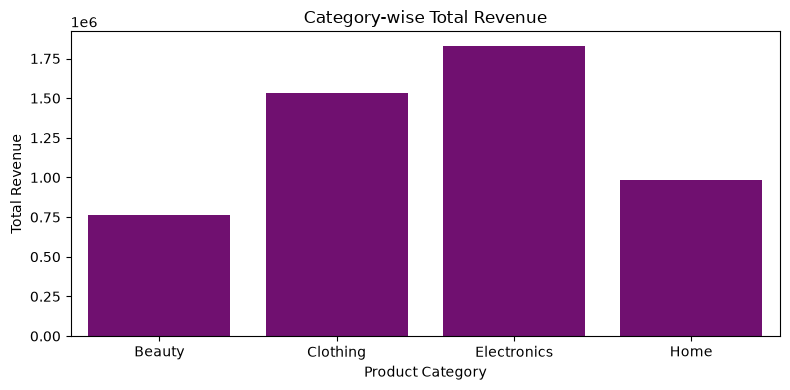

In [26]:
plt.figure(figsize=(8,4))
sns.barplot(df,x='product_category',y='revenue',estimator='sum',errorbar=None,color='purple')
plt.title("Category-wise Total Revenue")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()



**Observation** : Electronics generated the highest total revenue, while Beauty generated the lowest revenue. This shows that Electronics is the strongest revenue-generating category.

2. Region-wise Total Orders  - countplot

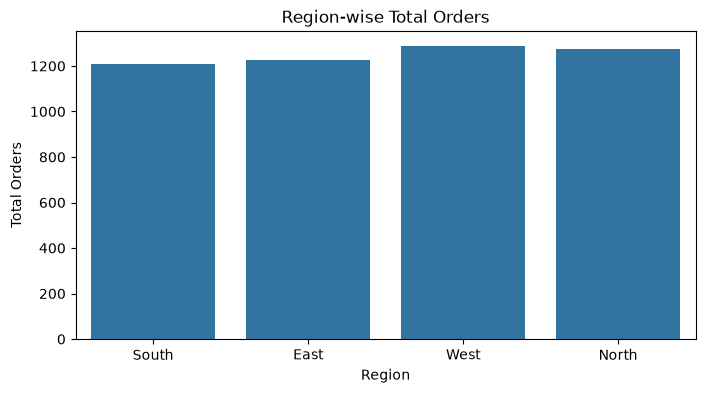

In [27]:
plt.figure(figsize=(8,4))
sns.countplot(df,x='region')
plt.title("Region-wise Total Orders")
plt.xlabel("Region")
plt.ylabel("Total Orders")
plt.show()

**Observation** : The West region had the highest number of orders (1,289), while the South region had the lowest (1,208).

3. Region-wise Revenue

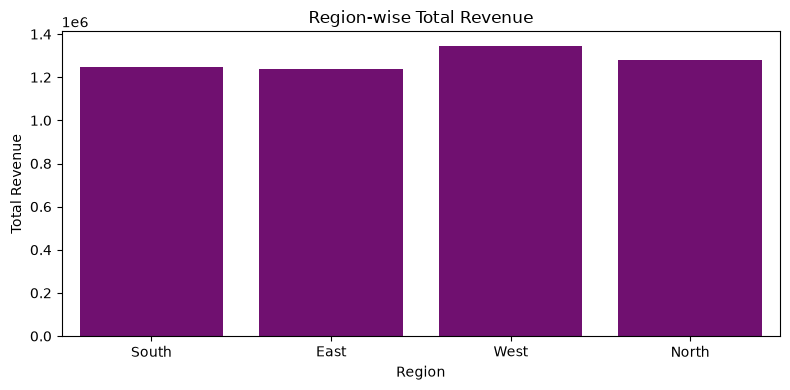

In [28]:
plt.figure(figsize=(8,4))
sns.barplot(df,x='region',y='revenue',estimator='sum',errorbar=None,color='purple')
plt.title("Region-wise Total Revenue")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()



**Observation** : The West region generated the highest total revenue, while the East region generated the lowest.

4. Payment Method — Count Plot

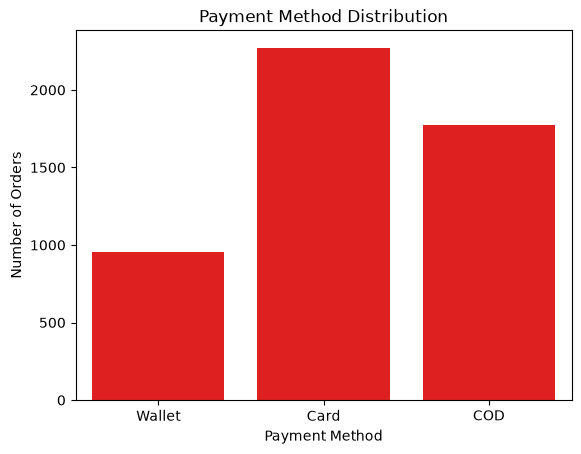

In [29]:
sns.countplot(data=df, x='payment_method',color='red')

plt.title('Payment Method Distribution')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
# plt.xticks(rotation=45)
plt.show()

**Observation** : Card was the most commonly used payment method, with 2,270 orders. Wallet was the least used, with 956 orders.

4. Month-wise Revenue

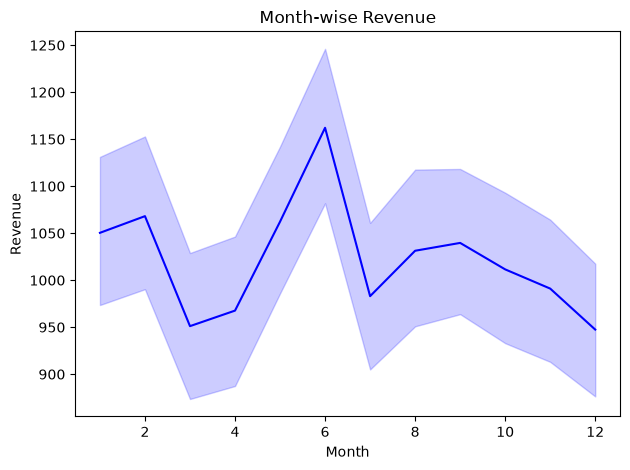

In [30]:
sns.lineplot(df,x='month',y='revenue',color = 'blue')
plt.title("Month-wise Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

**Observation** : Revenue was highest in May 2025 (₹156,079.98) and lowest in April 2024 (₹79,298.85).

### Conclusion

The E-Commerce Sales Analysis highlights key business insights using Python. Electronics generated the highest revenue, while Beauty generated the lowest. The West region recorded the highest number of orders, and Card was the most commonly used payment method. Monthly revenue changed over time, reaching its highest in May 2025. Overall, this analysis helps businesses understand sales performance, identify growth opportunities, and make better business decisions.

### Business Suggestions

1. **Increase Product Sales:** Promote Electronics products and use special offers to improve Beauty sales.

2. **Improve Regional Sales:** Focus on increasing sales in the East and South regions.

3. **Encourage Digital Payments:** Offer cashback and discounts to encourage Wallet payments.

4. **Plan Monthly Offers:** Provide special discounts during low-revenue months to increase sales.

5. **Manage Stock Effectively:** Keep sufficient stock of high-demand products to avoid shortages.

6. **Monitor Performance:** Regularly analyze sales and revenue to identify growth opportunities and make better business decisions.